# Session 13 lecture: HR: workforce analytics

<p class="lead">
An HR partner has to tell managers where the workforce is under strain: where people are leaving, where teams are growing or shrinking, and where roles are not being filled. This lecture shows how to count a workforce correctly over time, measure turnover with a fair denominator, and read recruitment data without hiding the roles that are still open.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/13_hr_workforce_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 12 lecture](12_marketing_campaigns_lecture.md). Write short answers; we discuss them together.

1. Campaign A converted 2% of 50,000 sessions and campaign B converted 10% of 500 sessions. Why is the average of the two rates (6%) not the overall conversion rate? How do you calculate the right one?
2. A campaign has a return on ad spend (ROAS) of 5. Say in plain words what that means, and why it does not prove the campaign **caused** those sales.
3. What does **incrementality** mean, and what kind of study measures it best?
4. A channel's cost per acquisition is calculated as total spend ÷ total conversions. Why is this better than averaging each day's cost per acquisition?
5. A channel spent nothing on one day but recorded two conversions. What should its ROAS be for that day, and how would you show it in a table?

---

## What you will be able to explain

1. The **grain** of employee, department-history and requisition tables, and why HR facts are **intervals** in time.
2. When an employee is **active on a date**, and why the exit date is the **first inactive day**.
3. How a **monthly headcount bridge** works: opening + hires − exits = closing.
4. **Average headcount**, **monthly turnover** and **annual turnover**, and why annual turnover is not the mean of monthly rates.
5. The **current-headcount trap**: why dividing past exits by today's headcount misleads.
6. Why a **transfer** changes department counts but is neither a hire nor an exit.
7. The difference between **tenure** of current employees and **completed service** of leavers.
8. **Time to fill** for accepted roles versus the **open age** of roles still open.
9. Why **small groups**, **privacy** and **fairness** limit what HR analysis can claim.

This lecture builds on weighted rates from the [Session 5 lecture](05_metrics_and_kpis_lecture.md) and on [How statistics can mislead](../foundations/misleading-statistics.md). In the **Lab** you rebuild the bridge, repair four broken calculations and recommend one investigation.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell, then the cell after it, which loads the three tables.

In [1]:
# HR data setup (synthetic). Run this cell first.
# Downloads the course's synthetic workforce data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

HR_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/hr-v1/"
HR_SHA256 = {
    "employees.csv": "7d59a66675d53b7d6de8cce6a4d3369ddd6268e51913e86f30e9560c019342a9",
    "department_history.csv": "12e6524a7838e9d5426c2bef116769ad850d5eaf11e10958a4e4ae13d21dca36",
    "recruitment.csv": "3a6c2046fd5cbb4a07d435f50e3d10e5df160314decd1e651718a5d0bd7fbc05",
}
HR_DATES = {
    "employees.csv": ["hire_date", "exit_date"],
    "department_history.csv": ["effective_from", "effective_to"],
    "recruitment.csv": ["opened_date", "offer_accepted_date", "hire_date"],
}
HR_DIR = os.environ.get("COURSE_HR_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_hr(name):
    """Load one hr-v1 file: 'employees.csv', 'department_history.csv' or 'recruitment.csv'."""
    if HR_DIR:
        with open(os.path.join(HR_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(HR_URL + name).read()
    if hashlib.sha256(data).hexdigest() != HR_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=HR_DATES[name])


print("HR setup complete.")

HR setup complete.


In [2]:
import datetime

import matplotlib.pyplot as plt
import numpy as np

ONE_DAY = datetime.timedelta(days=1)

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

employees = load_hr("employees.csv")
history = load_hr("department_history.csv")
requisitions = load_hr("recruitment.csv")
print("Employees:", len(employees), "| department intervals:", len(history), "| requisitions:", len(requisitions))

Employees: 520 | department intervals: 543 | requisitions: 160


---

## Part 1: The decision

> *HR partner: "The leadership team has asked me which workforce issue to look into next quarter. Is one team losing people faster than it can replace them? Is recruitment too slow somewhere? I can only take one investigation forward, so I need numbers I can defend."*

The decision is **which capacity or recruitment issue deserves a closer look**, not who to blame. A good answer shows, for the workforce over 2025:

| Evidence | Question it answers |
|---|---|
| A monthly **headcount bridge** | How many people did we have, and how did hires and exits change that? |
| **Turnover** with a fair denominator | Which teams lost a large share of the people they had? |
| **Department bridges** | Did a team shrink because people left, or because they moved to another team? |
| **Recruitment** times and **open roles** | Where are we slow to replace people? |

> **About the data**
>
> The three files are **synthetic** teaching data generated by the course for a fictional company. No real person is described. There are **no names and no demographic or protected attributes** (such as age, gender or ethnicity), on purpose. The observation **cutoff** is 2025-12-31: we know nothing that happened after that day.

---

## Part 2: Three tables, three grains

| Table | One row is | Key | Dates |
|---|---|---|---|
| `employees.csv` | One **employment spell** (one per employee here; nobody is rehired) | `employee_id` | `hire_date`, `exit_date` |
| `department_history.csv` | One **department assignment interval** | (`employee_id`, `effective_from`) | `effective_from`, `effective_to` |
| `recruitment.csv` | One **requisition** (an approved open role) | `requisition_id` | `opened_date`, `offer_accepted_date`, `hire_date` |

None of these tables has one row per month. Headcount for a month is something **we build** from the dates. Before building anything, check that the keys are unique and the dates make sense.

In [3]:
emp_ok = employees["exit_date"].isna() | (employees["exit_date"] > employees["hire_date"])
hist_ok = history["effective_to"].isna() | (history["effective_to"] > history["effective_from"])
checks = {
    "employees: one row per employee_id": employees["employee_id"].is_unique,
    "history: one row per (employee_id, effective_from)": not history.duplicated(["employee_id", "effective_from"]).any(),
    "requisitions: one row per requisition_id": requisitions["requisition_id"].is_unique,
    "every history row belongs to a known employee": history["employee_id"].isin(employees["employee_id"]).all(),
    "exit date is after hire date (when there is one)": emp_ok.all(),
    "each department interval ends after it starts": hist_ok.all(),
    "no hire or exit after the cutoff": (employees[["hire_date", "exit_date"]].max() <= CUTOFF).all(),
}
pd.Series(checks).to_frame("passes")

,passes
employees: one row per employee_id,True
"history: one row per (employee_id, effective_from)",True
requisitions: one row per requisition_id,True
every history row belongs to a known employee,True
exit date is after hire date (when there is one),True
each department interval ends after it starts,True
no hire or exit after the cutoff,True


Every check above should say `True`. One more thing to look at: the table includes people hired **long before 2025**. That is deliberate. Without them we could not know how many people were already working on 1 January 2025.

In [4]:
employees["hire_date"].dt.year.value_counts().sort_index().to_frame("employees hired")

,employees hired
hire_date,
2015,18
2016,7
2017,16
2018,22
2019,18
2020,34
2021,36
2022,48
2023,69


---

## Part 3: Intervals and "active on a date"

An employee is a **span of time**, not a single event. The contract for this data says:

| Field | Meaning |
|---|---|
| `hire_date` | The **first active day** |
| `exit_date` | The **first inactive day**: the day after the last day worked. Blank = still employed at the cutoff |

So an employee is **active on day d** when

*hire_date ≤ d* **and** *(exit_date is blank **or** exit_date > d)*.

Note the strict ">" for the exit: on their exit date the person is already gone. Someone whose last working day is 31 March has an exit date of **1 April**. Getting this one character wrong is the most common HR counting bug.

The two functions below turn that rule into code. They also work for department intervals if you pass the other column names.

In [5]:
def is_active(table, day, start="hire_date", end="exit_date"):
    """True for each row whose interval [start, end) contains `day`. A blank end means still open."""
    day = pd.Timestamp(day)
    return (table[start] <= day) & (table[end].isna() | (table[end] > day))


def active_on(table, day, start="hire_date", end="exit_date"):
    """How many rows are active on `day`."""
    return int(is_active(table, day, start, end).sum())


print("Active at the cutoff:", active_on(employees, CUTOFF))

Active at the cutoff: 389


---

## Part 4: A hand fixture across a month boundary

Real data hide the tricky cases among hundreds of rows. So we first build a **fixture**: six made-up employees, each chosen to test one boundary, and work out the answer by hand.

The month is **March 2025**. The rule for a month:

| Measure | Definition |
|---|---|
| **Opening** | Active on the **last day of the previous month** (28 February): the headcount as March begins |
| **Hires** | Hire dates inside March |
| **Exits** | Exit dates inside March |
| **Closing** | Active on the **last day of the month** (31 March) |

With these definitions, March's closing is exactly April's opening, and *closing = opening + hires − exits* always holds.

In [6]:
fixture = pd.DataFrame({
    "employee_id": ["A", "B", "C", "D", "E", "F"],
    "hire_date": pd.to_datetime(["2024-06-10", "2025-03-01", "2023-02-13", "2022-09-05", "2021-11-22", "2022-04-04"]),
    "exit_date": pd.to_datetime([None, None, "2025-03-01", "2025-03-17", "2025-04-01", None]),
    "story": [
        "Still employed",
        "Hired on 1 Mar",
        "Last day 28 Feb",
        "Leaves mid-March",
        "Last day 31 Mar",
        "Sales to Marketing 20 Mar",
    ],
})
fixture

,employee_id,hire_date,exit_date,story
0,A,2024-06-10,NaT,Still employed
1,B,2025-03-01,NaT,Hired on 1 Mar
2,C,2023-02-13,2025-03-01,Last day 28 Feb
3,D,2022-09-05,2025-03-17,Leaves mid-March
4,E,2021-11-22,2025-04-01,Last day 31 Mar
5,F,2022-04-04,NaT,Sales to Marketing 20 Mar


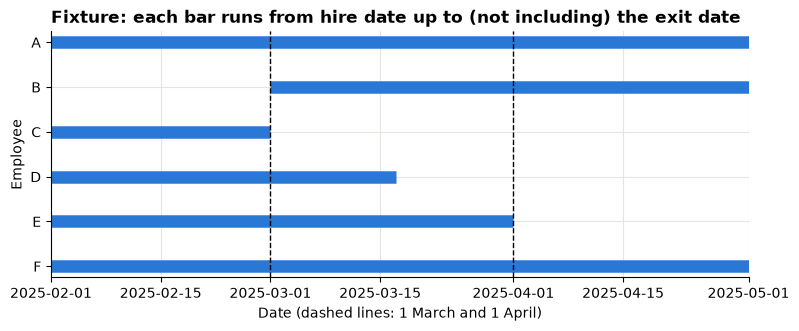

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
view_start, view_end = pd.Timestamp("2025-02-01"), pd.Timestamp("2025-05-01")
for i, row in fixture.iterrows():
    left = max(row["hire_date"], view_start)
    right = row["exit_date"] if pd.notna(row["exit_date"]) else view_end
    ax.hlines(i, left, min(right, view_end), linewidth=9, color="#2a78d6")
ax.axvline(pd.Timestamp("2025-03-01"), color="black", linestyle="--", linewidth=1)
ax.axvline(pd.Timestamp("2025-04-01"), color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(fixture)), fixture["employee_id"])
ax.invert_yaxis()
ax.set_xlim(view_start, view_end)
ax.set_title("Fixture: each bar runs from hire date up to (not including) the exit date")
ax.set_xlabel("Date (dashed lines: 1 March and 1 April)")
ax.set_ylabel("Employee")
plt.show()

> **Predict, then reveal**
>
> Using only the table and the chart, work out March's **opening**, **hires**, **exits** and **closing** for the company. Check that closing = opening + hires − exits. For each of C and E: are they in March's exits?

In [8]:
def month_bridge(table, month_start):
    """Opening, hires, exits and closing for the month that starts on `month_start`."""
    start = pd.Timestamp(month_start)
    end = start + pd.offsets.MonthEnd(0)                       # last day of the month
    return {
        "opening": active_on(table, start - ONE_DAY),  # active on the last day of the previous month
        "hires": int(table["hire_date"].between(start, end).sum()),
        "exits": int(table["exit_date"].between(start, end).sum()),
        "closing": active_on(table, end),                     # active on the last day of this month
    }


trace = pd.DataFrame({
    "in opening (active 28 Feb)": is_active(fixture, "2025-02-28"),
    "hire in March": fixture["hire_date"].between("2025-03-01", "2025-03-31"),
    "exit in March": fixture["exit_date"].between("2025-03-01", "2025-03-31"),
    "in closing (active 31 Mar)": is_active(fixture, "2025-03-31"),
})
trace.index = fixture["employee_id"]
display(trace)
print("March bridge:", month_bridge(fixture, "2025-03-01"))

,in opening (active 28 Feb),hire in March,exit in March,in closing (active 31 Mar)
employee_id,,,,
A,True,False,False,True
B,False,True,False,True
C,True,False,True,False
D,True,False,True,False
E,True,False,False,True
F,True,False,False,True


March bridge: {'opening': 5, 'hires': 1, 'exits': 2, 'closing': 4}


Read the person-by-person table above, then the totals:

1. **B**, hired on 1 March, is a **hire** in March and not part of the opening.
2. **C** has exit date 1 March. C was active on 28 February, so C is in the **opening**, and the exit belongs to **March**.
3. **D** leaves mid-month: opening yes, exit in March, closing no.
4. **E**'s last day is 31 March, so E is still in March's **closing**, and the exit belongs to **April**.
5. **F** changes department, which does not affect the **company** count at all. We come back to F in Part 8.

> **Check your understanding 1**
>
> An HR system stores the **last working day** instead of the first inactive day. An employee's last working day is 31 March. What exit date must you use under this course's contract, and in which month's exits does the person belong?

---

## Part 5: The monthly company bridge

The same function, run for each month of 2025 on the real employees, gives the **monthly bridge**. Two `assert` lines check it. An `assert` stops the notebook with an error if its condition is false, so a wrong bridge can never pass quietly.

In [9]:
months = pd.date_range("2025-01-01", "2025-12-01", freq="MS")

bridge = pd.DataFrame([month_bridge(employees, m) for m in months], index=months.strftime("%Y-%m"))
bridge.index.name = "month"

# Two checks that must always pass.
assert (bridge["closing"] == bridge["opening"] + bridge["hires"] - bridge["exits"]).all(), "bridge does not balance"
assert (bridge["opening"].iloc[1:].to_numpy() == bridge["closing"].iloc[:-1].to_numpy()).all(), "months do not chain"
print("Bridge balances in all 12 months, and each closing equals the next opening.")
bridge

Bridge balances in all 12 months, and each closing equals the next opening.


,opening,hires,exits,closing
month,,,,
2025-01,379,1,9,371
2025-02,371,6,9,368
2025-03,368,6,7,367
2025-04,367,8,2,373
2025-05,373,15,10,378
2025-06,378,36,8,406
2025-07,406,18,6,418
2025-08,418,12,18,412
2025-09,412,16,19,409


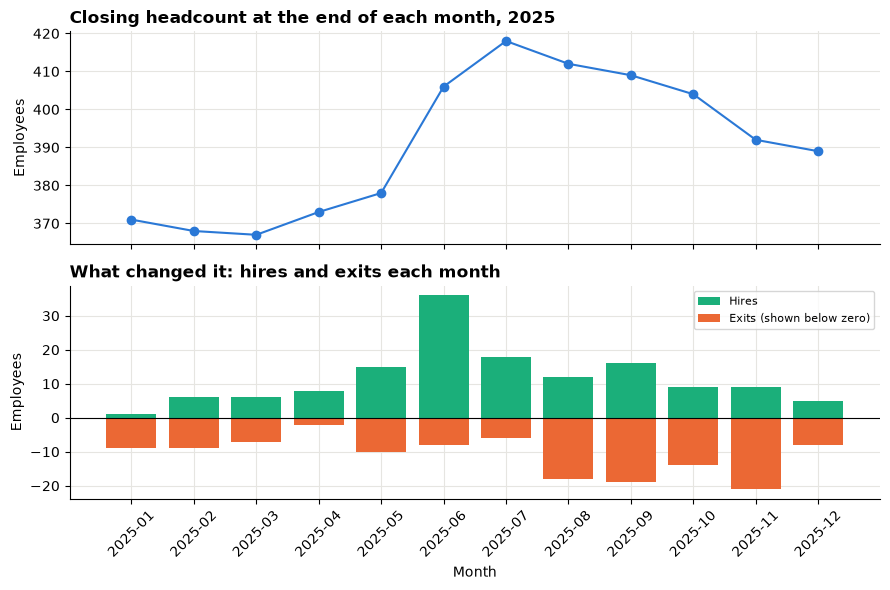

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
x = np.arange(len(bridge))
ax1.plot(x, bridge["closing"], marker="o", color="#2a78d6")
ax1.set_title("Closing headcount at the end of each month, 2025")
ax1.set_ylabel("Employees")
ax2.bar(x, bridge["hires"], color="#1baf7a", label="Hires")
ax2.bar(x, -bridge["exits"], color="#eb6834", label="Exits (shown below zero)")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("What changed it: hires and exits each month")
ax2.set_ylabel("Employees")
ax2.set_xticks(x, bridge.index, rotation=45)
ax2.set_xlabel("Month")
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

The top chart is the **stock** (how many people) and the bottom chart the **flows** (people in and out). Read them together: headcount rises in the months where the green bars outgrow the orange ones, and falls when exits outpace hires.

> **Check your understanding 2**
>
> A colleague's bridge has a month where closing ≠ opening + hires − exits. Name two different bugs that could cause it.

---

## Part 6: Average headcount and turnover

**Turnover** is the share of the workforce that left. The question is: share of **which** workforce? Headcount changes during the month, so we use the **average headcount** for the month, approximated as *(opening + closing) ÷ 2*.

| Measure | Formula |
|---|---|
| Monthly average headcount | (opening + closing) ÷ 2 (an approximation) |
| Monthly turnover | exits in the month ÷ monthly average headcount |
| Annual turnover | **exits in the year ÷ mean of the 12 monthly average headcounts** |

If an average headcount is 0, turnover is **not available**, not 0.

Exits in 2025: 131 | mean monthly average headcount: 390.2
Annual turnover: 33.6%


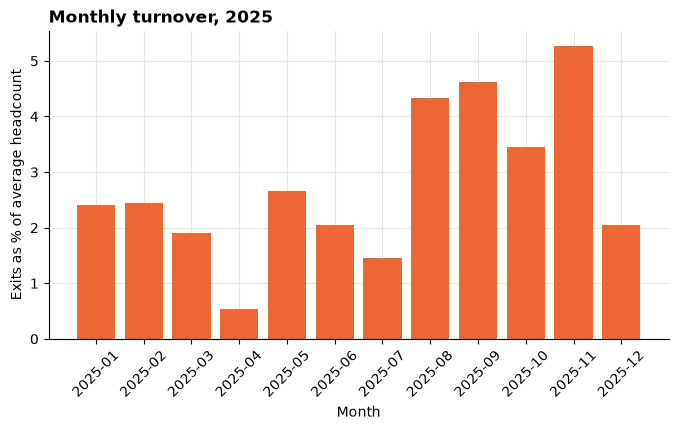

In [11]:
bridge["avg_headcount"] = (bridge["opening"] + bridge["closing"]) / 2
bridge["turnover"] = (bridge["exits"] / bridge["avg_headcount"]).where(bridge["avg_headcount"] > 0)

annual_exits = bridge["exits"].sum()
mean_headcount = bridge["avg_headcount"].mean()
annual_turnover = annual_exits / mean_headcount
print(f"Exits in 2025: {annual_exits} | mean monthly average headcount: {mean_headcount:,.1f}")
print(f"Annual turnover: {annual_turnover:.1%}")

ax = plt.gca()
ax.bar(bridge.index, bridge["turnover"] * 100, color="#eb6834")
ax.set_title("Monthly turnover, 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Exits as % of average headcount")
ax.tick_params(axis="x", rotation=45)
plt.show()

> **Predict, then reveal**
>
> Three colleagues each report "annual turnover" a different way: (a) annual exits ÷ the **current** headcount (December's closing), (b) the **mean of the 12 monthly rates**, (c) 12 × the mean of the monthly rates. Which one is furthest from the correct figure? Could any of them be exactly right?

In [12]:
current_headcount = bridge["closing"].iloc[-1]
methods = pd.Series({
    "Correct: exits ÷ mean of monthly average headcounts": annual_turnover,
    "(a) exits ÷ current (December closing) headcount": annual_exits / current_headcount,
    "(b) mean of the 12 monthly rates": bridge["turnover"].mean(),
    "(c) 12 × mean of the monthly rates": 12 * bridge["turnover"].mean(),
})
methods.map("{:.1%}".format).to_frame("reported annual turnover")

,reported annual turnover
Correct: exits ÷ mean of monthly average headcounts,33.6%
(a) exits ÷ current (December closing) headcount,33.7%
(b) mean of the 12 monthly rates,2.8%
(c) 12 × mean of the monthly rates,33.2%


Compare the rows in the table above:

- **(b)** is a **monthly** rate dressed up as an annual one, so it is far too small.
- **(c)** is close but not equal: averaging rates gives each month the same weight whatever its headcount, the same weighted-versus-unweighted problem as in Session 5. It is not the contract's definition.
- **(a)** happens to land near the correct figure **for the whole company**, because December's headcount is close to the year's average. That is luck, not method. The next part shows a team where it is badly wrong.

> **Check your understanding 3**
>
> Why is the denominator for annual turnover the **average** headcount over the year rather than the headcount on 31 December?

---

## Part 7: The current-headcount trap

To compare teams we need a bridge for each **department**. The function below is the department version of the company bridge. It uses the department intervals and has two extra columns, **transfers in** and **transfers out**, which Part 8 explains. For now look at headcount and exits.

In [13]:
def add_interval_flags(history):
    """Mark each employee's first and last department interval."""
    h = history.sort_values(["employee_id", "effective_from"]).copy()
    h["first_interval"] = ~h.duplicated("employee_id", keep="first")
    h["last_interval"] = ~h.duplicated("employee_id", keep="last")
    return h


def department_month(h, department, month_start):
    """Department bridge for one month: a transfer is neither a hire nor an exit."""
    d = h[h["department"] == department]
    start = pd.Timestamp(month_start)
    end = start + pd.offsets.MonthEnd(0)
    starts = d["effective_from"].between(start, end)
    ends = d["effective_to"].between(start, end)
    return {
        "opening": active_on(d, start - ONE_DAY, "effective_from", "effective_to"),
        "hires": int((starts & d["first_interval"]).sum()),
        "transfers_in": int((starts & ~d["first_interval"]).sum()),
        "exits": int((ends & d["last_interval"]).sum()),
        "transfers_out": int((ends & ~d["last_interval"]).sum()),
        "closing": active_on(d, end, "effective_from", "effective_to"),
    }


def department_bridge(h, department):
    """Monthly 2025 bridge for one department, checked to balance."""
    b = pd.DataFrame([department_month(h, department, m) for m in months], index=months.strftime("%Y-%m"))
    b.index.name = "month"
    expected = b["opening"] + b["hires"] + b["transfers_in"] - b["exits"] - b["transfers_out"]
    assert (b["closing"] == expected).all(), f"{department} bridge does not balance"
    return b


history = add_interval_flags(history)
departments = sorted(history["department"].unique())
dept_bridges = {d: department_bridge(history, d) for d in departments}
print("Departments:", ", ".join(departments))

Departments: Finance and Admin, Marketing, Operations, People, Sales, Technology


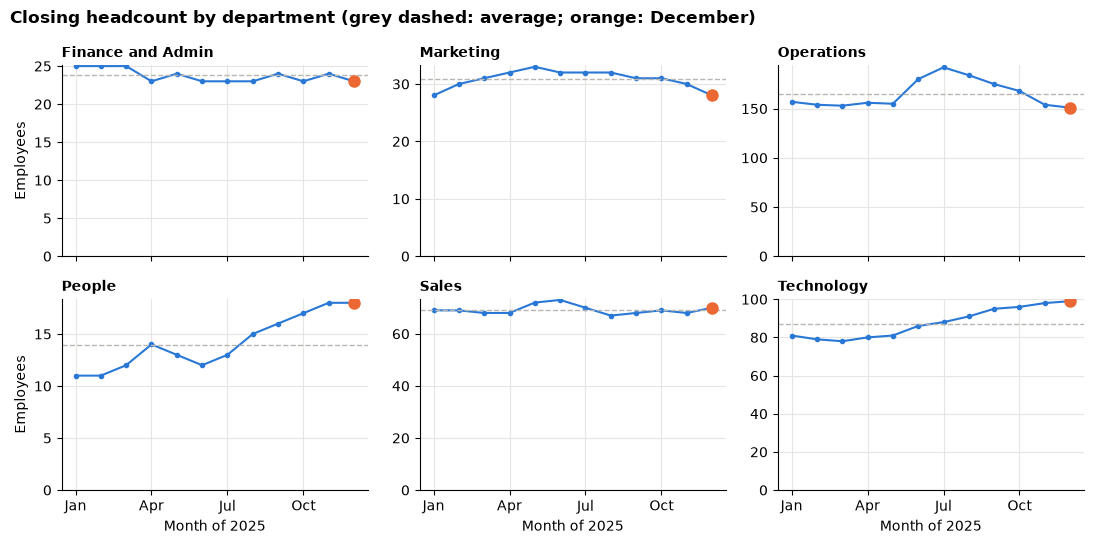

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True)
for ax, d in zip(axes.flat, departments):
    b = dept_bridges[d]
    avg = ((b["opening"] + b["closing"]) / 2).mean()
    ax.plot(range(12), b["closing"], marker="o", markersize=3, color="#2a78d6")
    ax.axhline(avg, color="#b8b6b0", linestyle="--", linewidth=1)
    ax.plot(11, b["closing"].iloc[-1], marker="o", markersize=8, color="#eb6834")
    ax.set_title(d, fontsize=10)
    ax.set_ylim(0, None)
for ax in axes[1]:
    ax.set_xticks(range(0, 12, 3), ["Jan", "Apr", "Jul", "Oct"])
    ax.set_xlabel("Month of 2025")
for ax in axes[:, 0]:
    ax.set_ylabel("Employees")
fig.suptitle("Closing headcount by department (grey dashed: average; orange: December)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

Look at **Operations** and **Technology** in the charts above. Operations grew sharply in the middle of the year and then shrank. Technology grew and stayed bigger. The orange dot (December, the "current" headcount) sits in a different place relative to the grey average line in each.

> **Predict, then reveal**
>
> For Operations and for Technology, will "exits ÷ current headcount" make turnover look **higher** or **lower** than the correct figure? Why?

In [15]:
rows = {}
for d, b in dept_bridges.items():
    avg = ((b["opening"] + b["closing"]) / 2).mean()
    exits = b["exits"].sum()
    rows[d] = {
        "Jan opening": b["opening"].iloc[0],
        "peak": b["closing"].max(),
        "Dec closing": b["closing"].iloc[-1],
        "exits": exits,
        "avg headcount": avg,
        "correct": exits / avg,
        "÷ current": exits / b["closing"].iloc[-1],
    }
dept_turnover = pd.DataFrame(rows).T
dept_turnover["gap (points)"] = (dept_turnover["÷ current"] - dept_turnover["correct"]) * 100
dept_turnover["small group"] = (dept_turnover["exits"] < 5) | (dept_turnover["avg headcount"] < 20)

dept_turnover.assign(**{
    c: dept_turnover[c].astype(int) for c in ["Jan opening", "peak", "Dec closing", "exits"]
} | {
    "avg headcount": dept_turnover["avg headcount"].map("{:.1f}".format),
    "correct": dept_turnover["correct"].map("{:.1%}".format),
    "÷ current": dept_turnover["÷ current"].map("{:.1%}".format),
    "gap (points)": dept_turnover["gap (points)"].map("{:+.1f}".format),
})

,Jan opening,peak,Dec closing,exits,avg headcount,correct,÷ current,gap (points),small group
Finance and Admin,25,25,23,4,23.8,16.8%,17.4%,+0.6,True
Marketing,30,33,28,6,30.9,19.4%,21.4%,+2.0,False
Operations,162,192,151,89,165.4,53.8%,58.9%,+5.1,False
People,12,18,18,4,13.9,28.7%,22.2%,-6.5,True
Sales,70,73,70,15,69.2,21.7%,21.4%,-0.2,False
Technology,80,99,99,13,86.9,15.0%,13.1%,-1.8,False


Read the **gap** column above:

- When a team **shrank** by December (Operations), the current headcount is **smaller** than the people who were actually exposed to leaving during the year, so dividing by it **overstates** turnover.
- When a team **grew** (Technology), the current headcount is **larger** than the average, so turnover is **understated**.
- Leavers are, by definition, not in the December headcount. December describes who **stayed**, not who was **exposed** to leaving during the year. **Current headcount cannot explain earlier turnover.**

The `small group` column flags departments with fewer than 5 exits or fewer than 20 people on average. Their rates can swing a lot when one person leaves; Part 11 comes back to this.

> **Check your understanding 4**
>
> A manager says: "Technology's turnover is the lowest, and it is even lower if you use today's headcount." What is wrong with the second half of the sentence?

---

## Part 8: Department bridges and transfers

Go back to employee **F** in the fixture, who moved from Sales to Marketing on 20 March. In `department_history.csv`, F has **two** rows: one Sales interval ending on 20 March and one Marketing interval starting on 20 March.

For a department, the bridge has two more flows:

*closing = opening + hires + transfers in − exits − transfers out*

| Event | Company bridge | Department bridge |
|---|---|---|
| Hire | Hire | Hire into the **first** department |
| Exit | Exit | Exit from the **last** department |
| Transfer | **Nothing changes** | Transfer **out** of one department, **in** to another |

A transfer is **not** a hire and **not** an exit. Counting it as both would invent a leaver and a joiner who never existed.

In [16]:
fixture_history = pd.DataFrame({
    "employee_id": ["A", "B", "C", "D", "E", "F", "F"],
    "department": ["Sales", "Marketing", "Sales", "Marketing", "Sales", "Sales", "Marketing"],
    "effective_from": pd.to_datetime(["2024-06-10", "2025-03-01", "2023-02-13", "2022-09-05",
                                      "2021-11-22", "2022-04-04", "2025-03-20"]),
    "effective_to": pd.to_datetime([None, None, "2025-03-01", "2025-03-17", "2025-04-01", "2025-03-20", None]),
})
fixture_history = add_interval_flags(fixture_history)

march = pd.DataFrame({d: department_month(fixture_history, d, "2025-03-01") for d in ["Sales", "Marketing"]}).T
march.loc["All departments"] = march.sum()
march

,opening,hires,transfers_in,exits,transfers_out,closing
Sales,4,0,0,1,1,2
Marketing,1,1,1,1,0,2
All departments,5,1,1,2,1,4


> **Predict, then reveal**
>
> Before reading the table above, work out Sales and Marketing by hand for March. Then check: does each row balance? Does the "All departments" row match the company bridge from Part 4? What happens to transfers in the total?

In the table above, transfers in and out cancel in the **All departments** row, so the department total matches the company bridge.

Now the real data. The cell below checks the same two facts for every month of 2025: transfers cancel across departments, and department totals add up to the company bridge.

In [17]:
flows = ["opening", "hires", "transfers_in", "exits", "transfers_out", "closing"]
all_departments = sum(b[flows] for b in dept_bridges.values())

assert (all_departments["transfers_in"] == all_departments["transfers_out"]).all(), "transfers do not cancel"
for col in ["opening", "hires", "exits", "closing"]:
    assert (all_departments[col] == bridge[col]).all(), f"department {col} do not add up to the company"
print("Transfers cancel every month, and department totals equal the company bridge.")
print("Transfers between departments in 2025:", all_departments["transfers_in"].sum())

Transfers cancel every month, and department totals equal the company bridge.
Transfers between departments in 2025: 23


One department where transfers matter is **People** (the HR team itself). Its bridge is below.

In [18]:
dept_bridges["People"]

,opening,hires,transfers_in,exits,transfers_out,closing
month,,,,,,
2025-01,12,0,0,1,0,11
2025-02,11,0,0,0,0,11
2025-03,11,1,0,0,0,12
2025-04,12,0,2,0,0,14
2025-05,14,0,0,1,0,13
2025-06,13,0,1,1,1,12
2025-07,12,1,0,0,0,13
2025-08,13,1,1,0,0,15
2025-09,15,0,2,1,0,16


Read the `hires` and `transfers_in` columns above: much of People's growth came from colleagues moving in from other teams, not from recruitment. A report that only counted hires would miss how this team grew; a report that counted transfers as hires would claim recruitment that never happened.

> **Check your understanding 5**
>
> Sales lost 10 people in a quarter: 6 exits and 4 transfers to Marketing. The Sales manager calls it "10 leavers". What would you correct, and what would the company-level exit count for that quarter include?

---

## Part 9: Tenure versus completed service

Two different questions, often confused:

| Measure | Who | Formula |
|---|---|---|
| **Tenure at the cutoff** | Employees **active** on 2025-12-31 only | cutoff − hire date |
| **Completed service** | **Leavers** only | exit date − hire date |

If you compute "cutoff − hire date" for **everyone**, leavers get credit for time after they left. If you mix the two groups, you blend a still-growing number with a finished one.

In [19]:
active_now = employees[is_active(employees, CUTOFF)]
leavers = employees[employees["exit_date"].notna()]
tenure_days = (CUTOFF - active_now["hire_date"]).dt.days
service_days = (leavers["exit_date"] - leavers["hire_date"]).dt.days
wrong_days = (CUTOFF - employees["hire_date"]).dt.days

pd.DataFrame({
    "people": [len(tenure_days), len(service_days), len(wrong_days)],
    "median days": [tenure_days.median(), service_days.median(), wrong_days.median()],
    "median years (approx.)": [tenure_days.median() / 365.25, service_days.median() / 365.25,
                               wrong_days.median() / 365.25],
}, index=["Tenure of active employees", "Completed service of leavers", "Wrong: everyone to the cutoff"]).round(1)

,people,median days,median years (approx.)
Tenure of active employees,389,783.00,2.10
Completed service of leavers,131,564.00,1.50
Wrong: everyone to the cutoff,520,772.00,2.10


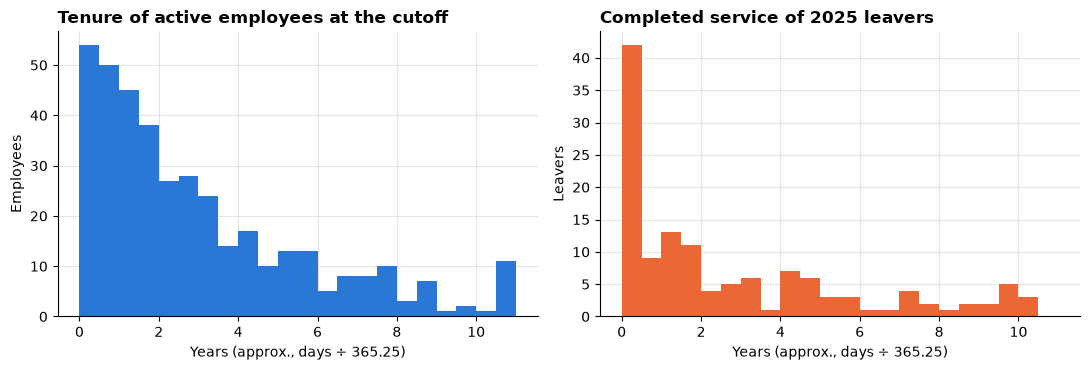

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
bins = np.arange(0, 11.5, 0.5)
ax1.hist(tenure_days / 365.25, bins=bins, color="#2a78d6")
ax1.set_title("Tenure of active employees at the cutoff")
ax1.set_xlabel("Years (approx., days ÷ 365.25)")
ax1.set_ylabel("Employees")
ax2.hist(service_days / 365.25, bins=bins, color="#eb6834")
ax2.set_title("Completed service of 2025 leavers")
ax2.set_xlabel("Years (approx., days ÷ 365.25)")
ax2.set_ylabel("Leavers")
fig.tight_layout()
plt.show()

The two histograms above have different shapes because they describe different people. Many leavers left within their first year or two, while the active workforce includes long-serving staff. Report them **separately**, with labels saying who is included.

> **Check your understanding 6**
>
> A dashboard tile says "Average tenure: 3.1 years". What two questions would you ask before using it?

---

## Part 10: Recruitment: time to fill and open age

Each requisition has a `status`:

| Status | Meaning | What we can measure |
|---|---|---|
| `filled` | Offer accepted and the person started by the cutoff | Time to fill |
| `accepted` | Offer accepted, start date after the cutoff | Time to fill |
| `open` | No accepted offer yet at the cutoff | **Open age** = cutoff − opened date |
| `canceled` | The role was withdrawn | Neither; count it and say so |

**Time to fill** = offer accepted date − opened date. An open role has **no** time to fill yet. Its open age is a **lower bound**: the role will take at least that long. Recording it as 0 days, or dropping it silently, makes slow teams look fast.

In [21]:
req = requisitions.copy()
req["days_to_fill"] = (req["offer_accepted_date"] - req["opened_date"]).dt.days          # blank if not accepted
req["open_age_days"] = (CUTOFF - req["opened_date"]).dt.days.where(req["status"] == "open")  # open roles only

print(req["status"].value_counts().to_string())
recruit = req.groupby("department").agg(
    accepted=("days_to_fill", "count"),
    median_days_to_fill=("days_to_fill", "median"),
    open_roles=("open_age_days", "count"),
    oldest_open_age=("open_age_days", "max"),
)
recruit

status
filled      143
canceled      8
open          5
accepted      4


,accepted,median_days_to_fill,open_roles,oldest_open_age
department,,,,
Finance and Admin,2,40.00,1,6.00
Marketing,1,23.00,2,43.00
Operations,88,18.00,0,NaN
People,4,39.00,0,NaN
Sales,17,41.00,0,NaN
Technology,35,54.00,2,75.00


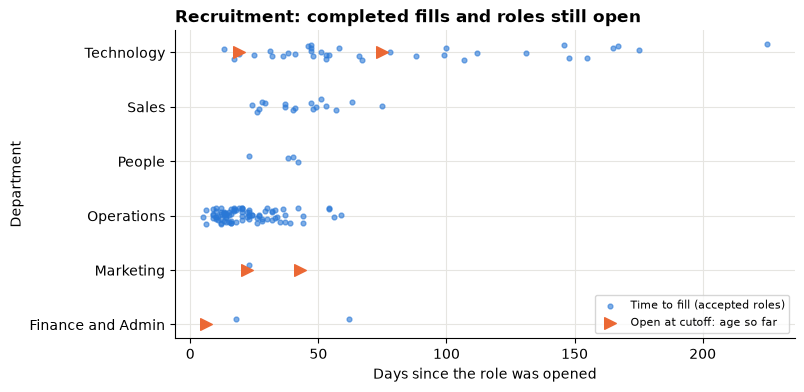

In [22]:
jitter = np.random.default_rng(seed=13)
order = list(recruit.index)
ax = plt.gca()
for i, d in enumerate(order):
    filled = req.loc[(req["department"] == d) & req["days_to_fill"].notna(), "days_to_fill"]
    ax.scatter(filled, i + jitter.uniform(-0.15, 0.15, len(filled)), s=12, color="#2a78d6", alpha=0.6,
               label="Time to fill (accepted roles)" if i == 0 else None)
    still_open = req.loc[(req["department"] == d) & req["open_age_days"].notna(), "open_age_days"]
    ax.scatter(still_open, [i] * len(still_open), s=70, marker=">", color="#eb6834",
               label="Open at cutoff: age so far" if i == len(order) - 1 else None)
ax.set_yticks(range(len(order)), order)
ax.set_title("Recruitment: completed fills and roles still open")
ax.set_xlabel("Days since the role was opened")
ax.set_ylabel("Department")
ax.legend(fontsize=8, loc="lower right")
plt.show()

> **Predict, then reveal**
>
> Someone fills the blank `days_to_fill` of open roles with **0** before taking the median. Which departments' medians will move, and in which direction?

In [23]:
zero_filled = req[req["status"] != "canceled"].assign(days=lambda t: t["days_to_fill"].fillna(0))
pd.DataFrame({
    "correct median (accepted only)": recruit["median_days_to_fill"],
    "wrong: open roles as 0 days": zero_filled.groupby("department")["days"].median(),
    "open roles": recruit["open_roles"],
})

,correct median (accepted only),wrong: open roles as 0 days,open roles
department,,,
Finance and Admin,40.00,18.00,1
Marketing,23.00,0.00,2
Operations,18.00,18.00,0
People,39.00,39.00,0
Sales,41.00,41.00,0
Technology,54.00,53.00,2


Departments with open roles get a **faster-looking** median when those roles are recorded as 0 days, which is exactly backwards: those roles are the slowest of all. Show completed fills and open ages **side by side**, as the chart does.

> **Check your understanding 7**
>
> Why is "time to start" (hire date − opened date) a different measure from time to fill? Which roles would be missing from a time-to-start average?

---

## Part 11: Small groups, privacy and fairness

HR data describe **people**, so the limits matter as much as the numbers.

| Risk | What it looks like | What to do |
|---|---|---|
| **Unstable rates** | A team of 15 with 4 exits: one more leaver moves its turnover by several points | Flag or **combine** groups with fewer than about 5 people or events; do not rank them |
| **Re-identification** | "1 exit in People, Corporate job family, November" points to one person even without a name | Suppress small cells (show "<5"), report at a coarser level |
| **Unfair inference** | "Team X has high turnover, so its manager is bad" or "these people are worse workers" | Descriptive data cannot show **quality**, **discrimination** or **causes** |

The threshold of 5 is a **teaching rule of thumb**, not a privacy guarantee or a statistical law. Real HR work follows the organisation's data-protection rules.

The cell below counts 2025 exits by department and job family, then **suppresses** small cells before anyone sees them.

In [24]:
last_department = history[history["last_interval"] & history["effective_to"].notna()]
exits_by = last_department.merge(employees[["employee_id", "job_family"]], on="employee_id")
counts = pd.crosstab(exits_by["department"], exits_by["job_family"])

suppressed = counts.astype(object).where((counts >= 5) | (counts == 0), "<5")
suppressed

job_family,Corporate,Engineering,Marketing,Sales,Warehouse
department,,,,,
Finance and Admin,<5,0,0,0,0
Marketing,0,0,5,0,<5
Operations,0,0,0,0,89
People,<5,0,0,0,0
Sales,0,0,0,14,<5
Technology,0,12,0,<5,0


In the table above, every cell for the small departments, and every unusual department and job-family pairing, is suppressed. That is not a failure: it tells you that this breakdown is **too fine** for those groups, and that the honest comparison is at department level, with small departments flagged or combined.

> **Check your understanding 8**
>
> A director asks for "turnover by department **and** by month, so I can see exactly when People lost staff". What would you send instead, and why?

---

## Part 12: Worked case: where is the workforce under strain?

We put the evidence together. Monthly turnover by department is too noisy for small teams, so we use **quarters**, and we **combine** the three small corporate departments (Finance and Admin, Marketing, People) into one group. Each quarter's turnover = exits in the quarter ÷ mean of its three monthly average headcounts.

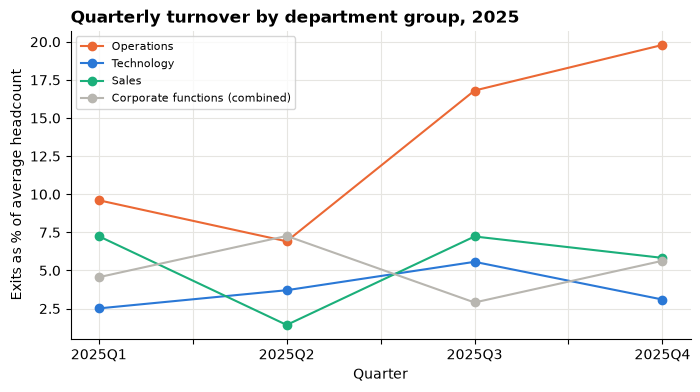

,Operations,Technology,Sales,Corporate functions (combined)
2025Q1,9.6%,2.5%,7.2%,4.6%
2025Q2,6.9%,3.7%,1.4%,7.3%
2025Q3,16.8%,5.6%,7.2%,2.9%
2025Q4,19.8%,3.1%,5.8%,5.6%


In [25]:
groups = {"Operations": ["Operations"], "Technology": ["Technology"], "Sales": ["Sales"],
          "Corporate functions (combined)": ["Finance and Admin", "Marketing", "People"]}
quarter = pd.PeriodIndex(months, freq="Q").astype(str)

trend = {}
for name, members in groups.items():
    b = sum(dept_bridges[d][["opening", "closing", "exits"]] for d in members)
    b["avg"] = (b["opening"] + b["closing"]) / 2
    q = b.groupby(quarter).agg(exits=("exits", "sum"), avg=("avg", "mean"))
    trend[name] = q["exits"] / q["avg"]
trend = pd.DataFrame(trend)

ax = trend.mul(100).plot(marker="o", color=["#eb6834", "#2a78d6", "#1baf7a", "#b8b6b0"])
ax.set_title("Quarterly turnover by department group, 2025")
ax.set_xlabel("Quarter")
ax.set_ylabel("Exits as % of average headcount")
ax.legend(fontsize=8)
plt.show()
trend.map("{:.1%}".format)

The chart above shows one group pulling away from the others in the second half of the year. Before writing a note, check the **mix**: which job families does each department employ? A difference between departments may really be a difference between kinds of work.

In [26]:
active_mix = history[is_active(history, CUTOFF, "effective_from", "effective_to")].merge(
    employees[["employee_id", "job_family"]], on="employee_id")
pd.crosstab(active_mix["department"], active_mix["job_family"], normalize="index").map("{:.0%}".format)

job_family,Corporate,Engineering,Marketing,Sales,Warehouse
department,,,,,
Finance and Admin,91%,4%,0%,0%,4%
Marketing,0%,7%,89%,0%,4%
Operations,0%,0%,0%,1%,99%
People,78%,11%,0%,6%,6%
Sales,0%,1%,1%,96%,1%
Technology,0%,97%,0%,2%,1%


Finally, a draft decision note. Every number in it comes from the tables above, through the code; nothing is typed by hand.

In [27]:
ops = dept_bridges["Operations"]
ops_row = dept_turnover.loc["Operations"]
print(
    f"Operations started 2025 with {ops['opening'].iloc[0]} people, peaked at {ops['closing'].max()} "
    f"in {ops['closing'].idxmax()} and ended the year with {ops['closing'].iloc[-1]}. "
    f"It recorded {int(ops_row['exits'])} exits, an annual turnover of {ops_row['correct']:.0%} "
    f"against {annual_turnover:.0%} for the whole company (both on average headcount). "
    f"Its roles are almost all Warehouse. It had {int(recruit.loc['Operations', 'open_roles'])} open roles "
    f"at the cutoff, and accepted roles took a median of {recruit.loc['Operations', 'median_days_to_fill']:.0f} days to fill."
)

Operations started 2025 with 162 people, peaked at 192 in 2025-07 and ended the year with 151. It recorded 89 exits, an annual turnover of 54% against 34% for the whole company (both on average headcount). Its roles are almost all Warehouse. It had 0 open roles at the cutoff, and accepted roles took a median of 18 days to fill.


The note above says **what** happened, not **why**. Before recommending an investigation of Operations retention, an HR partner would list the alternative explanations and the evidence that would separate them:

| Possible explanation | Extra evidence needed |
|---|---|
| A planned **seasonal** peak with fixed-term contracts that ended as intended | Contract type and planned end dates (not in this data) |
| New starters leaving early (onboarding, shift patterns, pay) | Exits by length of service; exit-interview themes |
| A change in demand, so fewer people were needed | Workload or volume data for the same months |
| Recording issues (for example, transfers misfiled as exits) | The department bridge checks in Part 8, already passed |

And the limits: this is synthetic, descriptive data; it cannot show that any manager, policy or group of people **caused** the pattern, and it says nothing about anyone's performance.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| Who was employed on a date? | hire ≤ d and (no exit or exit > d) | Treating the exit date as the last working day |
| How did headcount change? | Monthly bridge with `assert` checks | Missing pre-2025 hires; months that do not chain |
| What share left? | Exits ÷ average headcount | Dividing by current headcount |
| What was the annual rate? | Annual exits ÷ mean of 12 monthly averages | Averaging (or summing) monthly rates |
| Why did a team shrink? | Department bridge with transfers | Counting transfers as hires and exits |
| How long have people stayed? | Tenure (active) vs completed service (leavers) | Mixing the two, or counting leavers to the cutoff |
| How fast do we hire? | Time to fill, plus open age shown separately | Open roles as 0 days, or dropped silently |
| Can we compare every group? | Flag or combine groups under about 5; suppress small cells | Ranking tiny teams; inferring quality, bias or causes |

---

## Quiz

Answer these at the start of the next lecture, on **dashboards and storytelling**: turning analysis like today's into something a busy manager understands in a minute. Use common sense. Write short answers.

1. A manager will look at your dashboard for 30 seconds. What should they see first?
2. A chart title says "Monthly turnover by department". Rewrite it as a title that states the main message.
3. You have 12 charts from today's analysis. How would you decide which three to put in front of the leadership team?
4. Why might the same turnover finding need a different presentation for the HR director and for the Operations manager?
5. A story is often told as **situation → complication → resolution**. Fill in those three parts for the Operations finding from Part 12, in one sentence each.
6. Name one thing a dashboard should say about the data's limits, and where on the page you would put it.

---

## Lab briefing

In the **Lab** you:

1. Load the three tables and check keys and date order.
2. Rebuild the monthly company bridge with assertions, then average headcount and turnover.
3. Compare department turnover with the correct and the current-headcount denominators.
4. Build a department bridge with transfers, a tenure distribution, and a recruitment comparison that keeps open roles visible.
5. Challenge: repair four broken calculations, then recommend one capacity or recruitment investigation.

Open the [Session 13 lab](13_hr_workforce_lab.md).